## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00334ms.
00: Found the following number of samples per ticker: SPX: 2616.
00: Found date range 2015-01-02 to 2025-07-01 with 2616 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2078 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.34s.
/done


## AEC

Cleaning up memory... done.
['ask_vol', 'bdte', 'bid_vol', 'call_ask', 'call_bid', 'call_opt_id', 'df', 'expiry_id', 'fit1_vol', 'fitX_vol', 'fwd', 'fwd_ref', 'is_am', 'is_american', 'is_valid', 'log_open_interest', 'log_volume', 'mask_arb_free', 'mkt_call_ask', 'mkt_call_bid', 'mkt_call_log_open_interest', 'mkt_call_log_volume', 'mkt_put_ask', 'mkt_put_bid', 'mkt_put_log_open_interest', 'mkt_put_log_volume', 'nms', 'nms_atm', 'pure_ask_delta', 'pure_ask_dk', 'pure_ask_gamma', 'pure_ask_price', 'pure_ask_theta', 'pure_ask_vega', 'pure_bid_delta', 'pure_bid_dk', 'pure_bid_gamma', 'pure_bid_price', 'pure_bid_theta', 'pure_bid_vega', 'pure_fit1_delta', 'pure_fit1_dk', 'pure_fit1_gamma', 'pure_fit1_price', 'pure_fit1_theta', 'pure_fit1_vega', 'pure_fitX_delta', 'pure_fitX_dk', 'pure_fitX_gamma', 'pure_fitX_price', 'pure_fitX_theta', 'pure_fitX_vega', 'pure_strike', 'put_opt_id', 'spot_prev', 'spot_ref', 'spot_ret', 'strike', 'time_y', 'tte_y']
['ask_vol', 'bdte', 'bid_vol', 'call_ask', 'ca

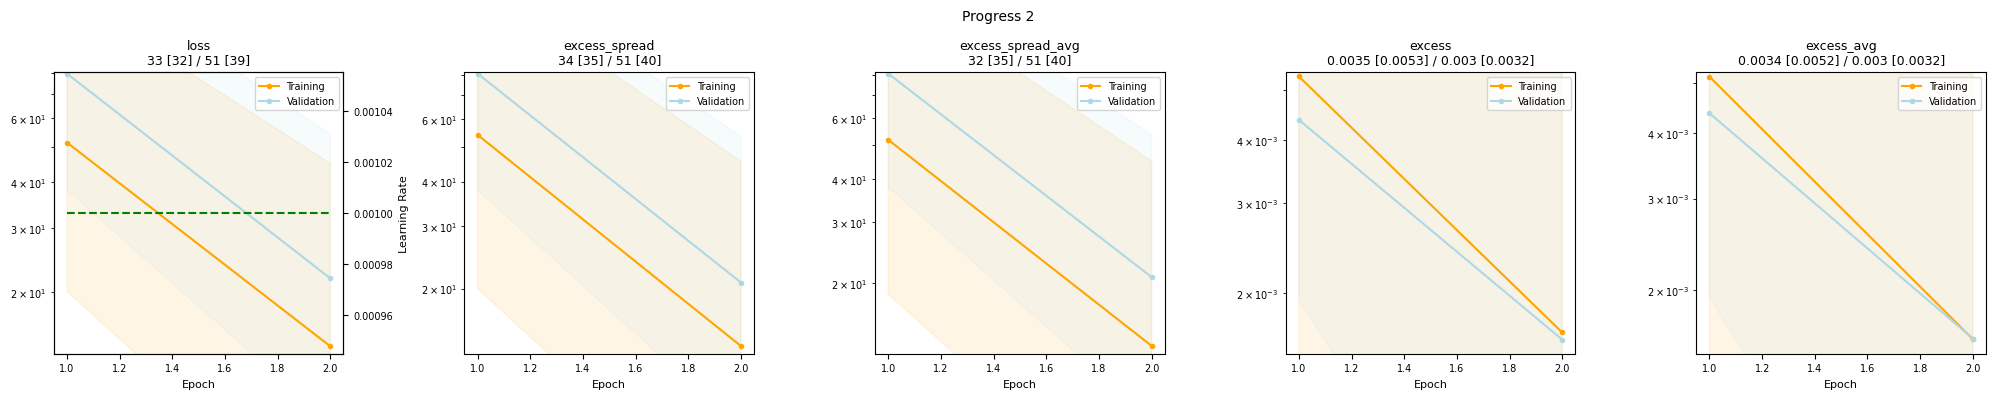

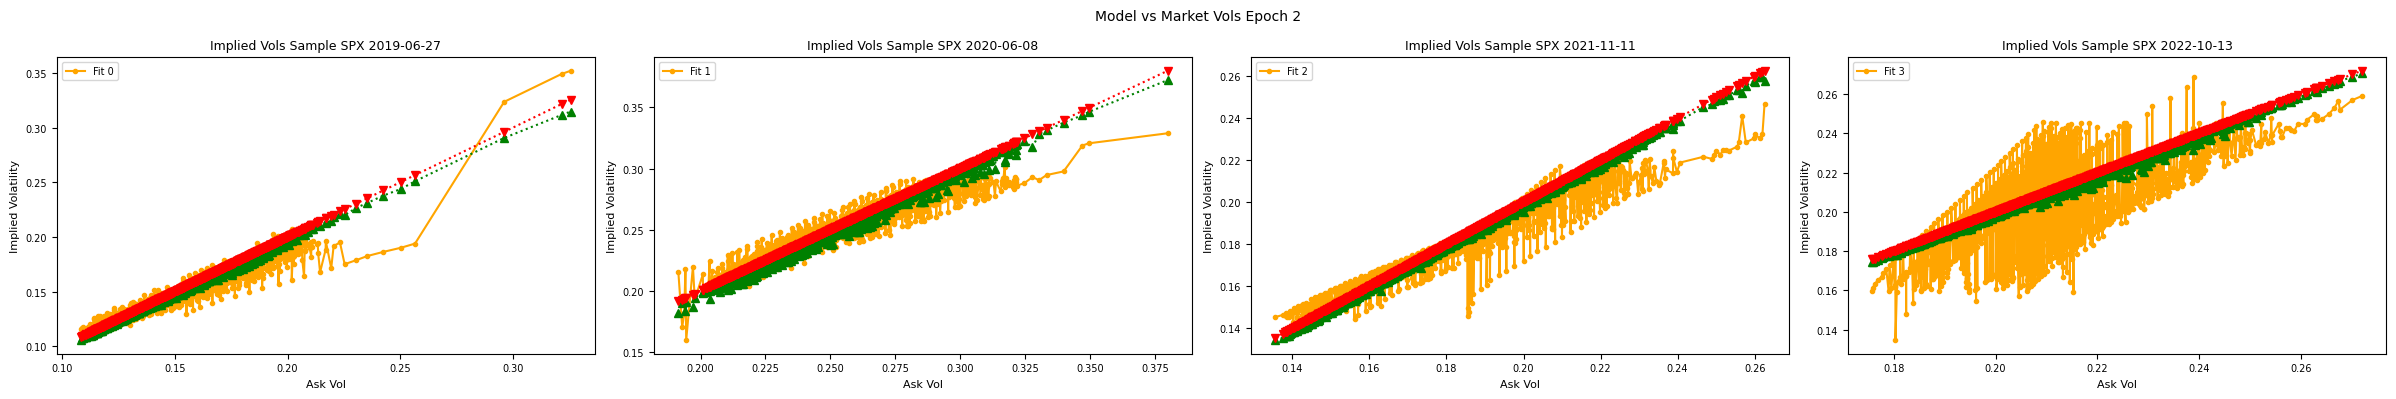

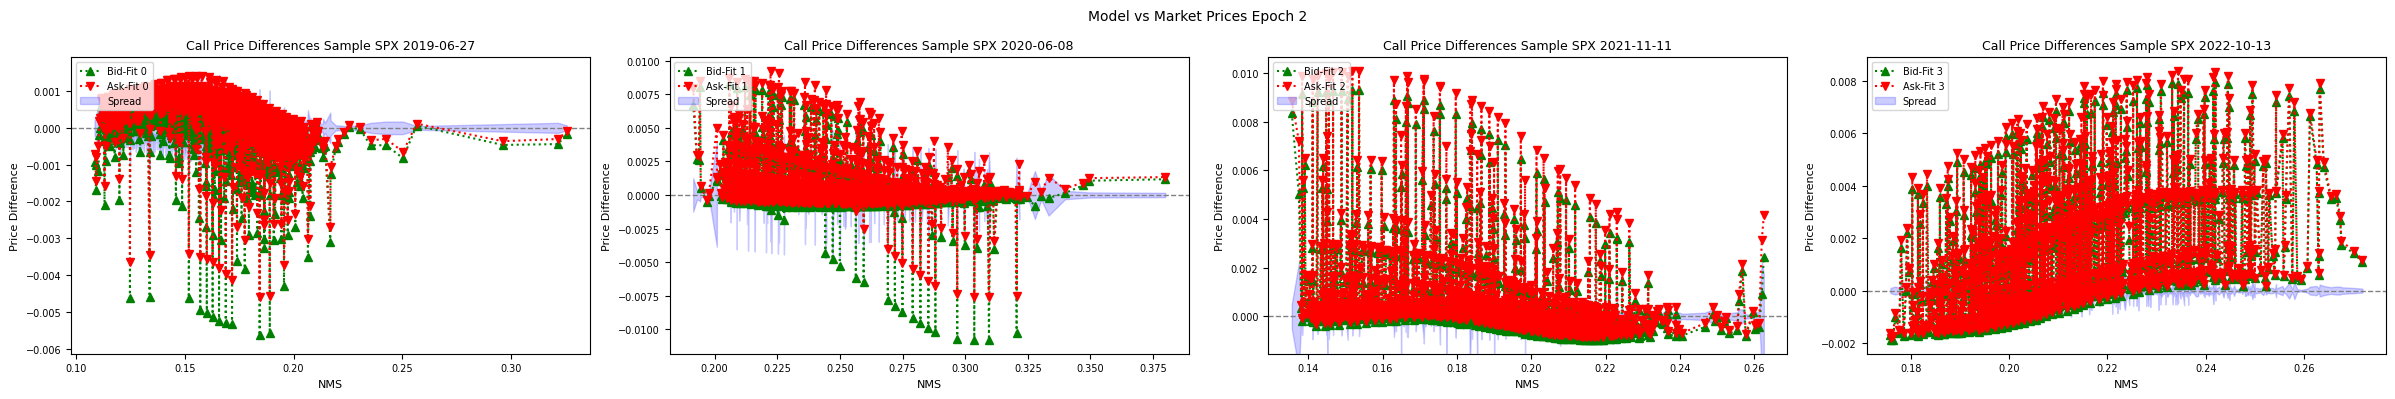

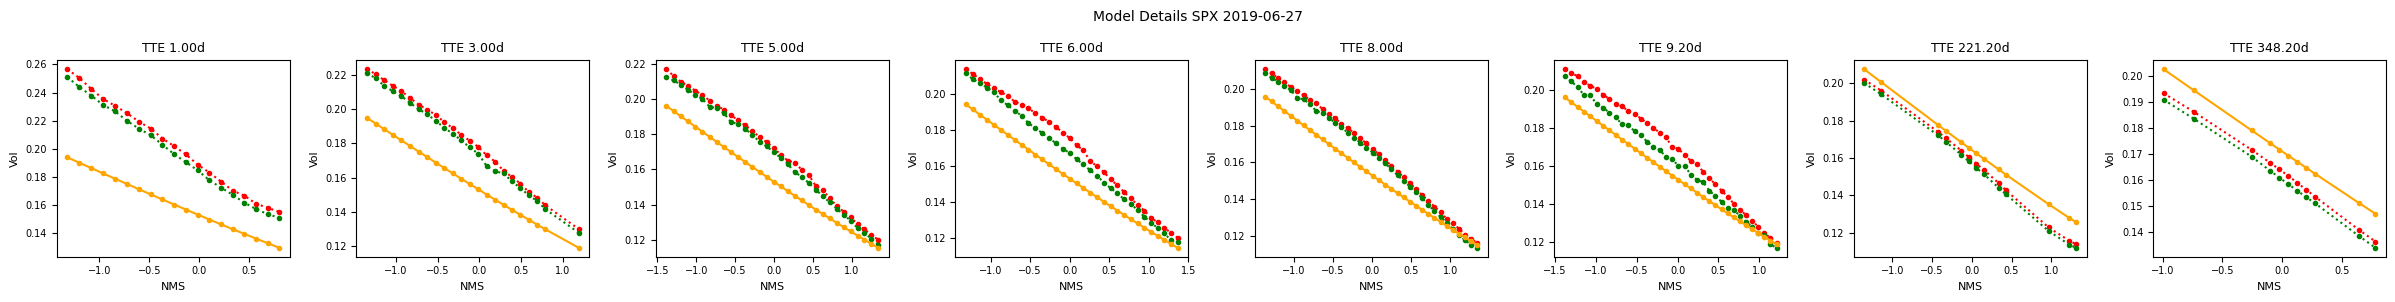

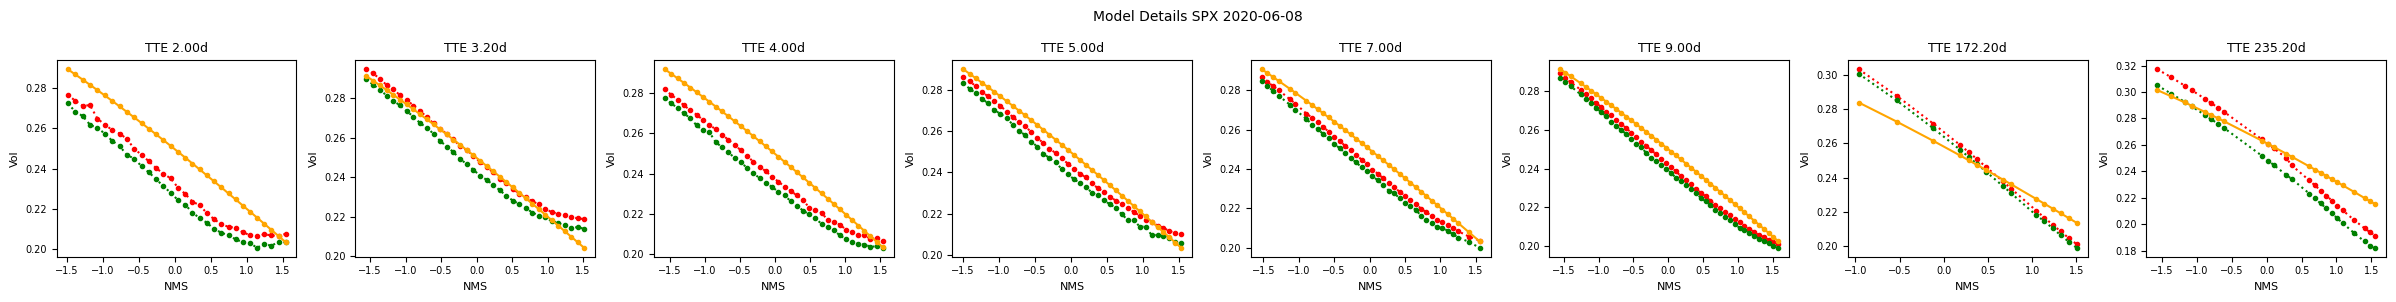

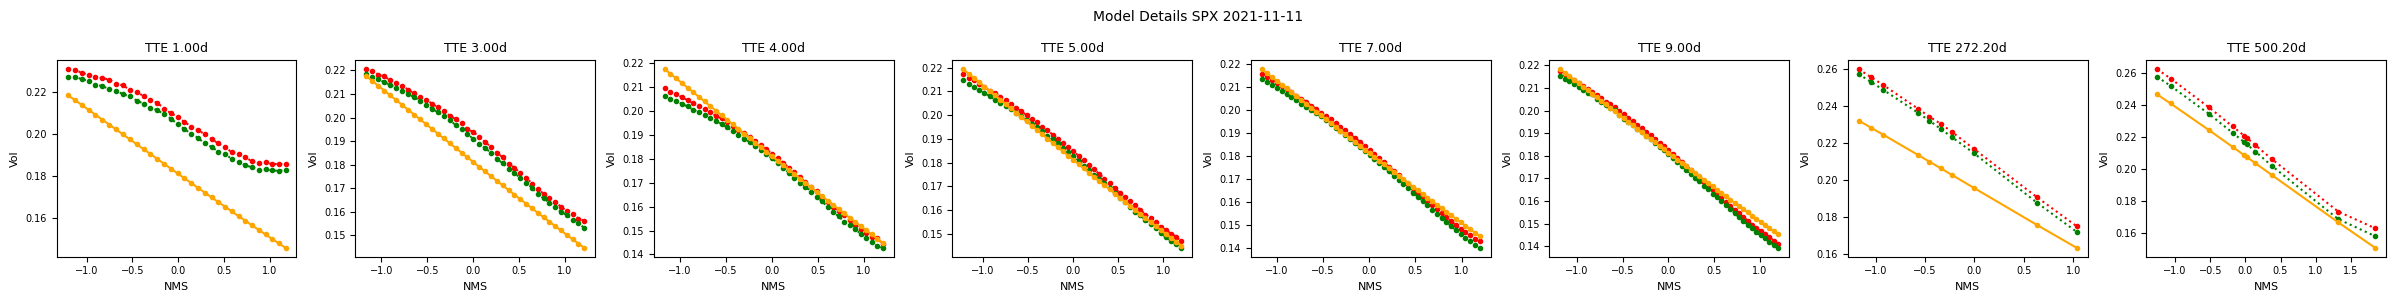

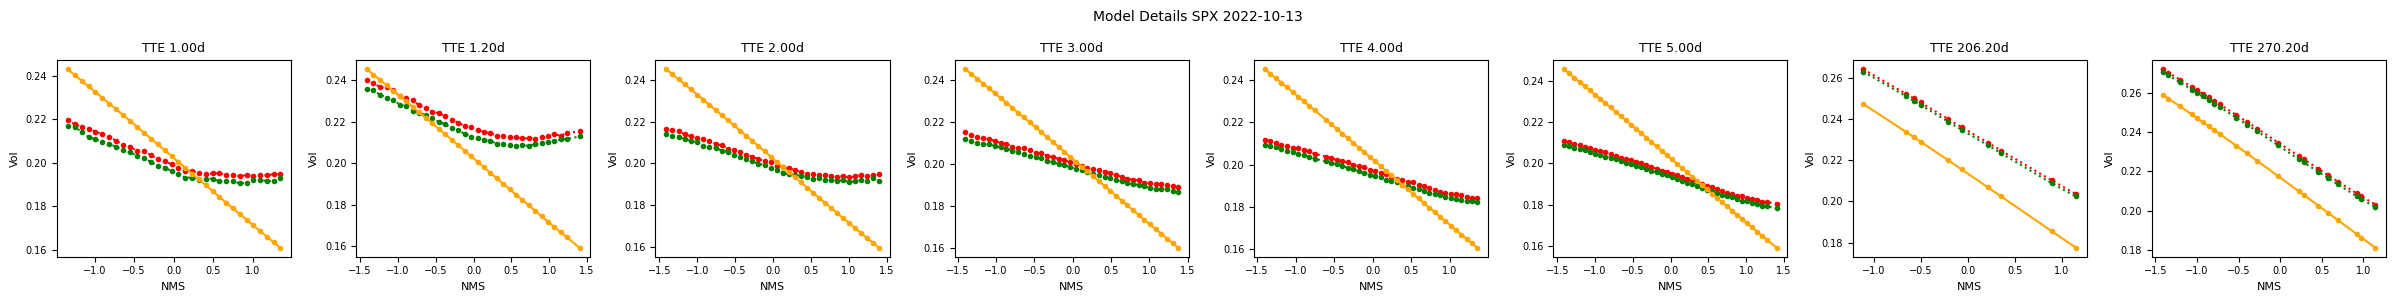

00: Training 'train_vol_vol_simple' epoch 2/1000 error avg trn 51.79; val 14.23/21.84 [1:01 0.97s 0.95s]. LR: 1.00e-03, GN 172.3, excess_weighted: 0.0008631/0.0009318, excess_weighted_avg: 0.001089/0.001041, excess_spread: 13.78/20.8, excess_spread_avg: 13.16/20.8, excess: 0.00167/0.001617, excess_avg: 0.001612/0.001617. ETA: 18:49:35.
00: Training epoch 3/1000 mini batch 41/100 with learning rate 1.00e-03: so far this took 12s...   

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 128,
    fit_average = True,

    encoder = DeepSetEncoderFactory(
        num_compress = 128,
        inside_tanh = True,
        set_config = FeedForward.Config(
            num_depth = 3,
            num_width = 64,
            activation = 'ReLU',
        ),
        fix_config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',    
        )
    ),
)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.3", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, val_batch_size=512 )
